<a href="https://colab.research.google.com/github/arsath-2109/AI_POWERED_SELECTIVE_WEEDING_MACHINE/blob/main/AI_POWERED_SELECTIVE_WEEDING_MACHINE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI Paddy Weed Detection — Using Your Uploaded YOLOv8-OBB Dataset



## 1. Install packages

In [2]:
!pip -q install -U ultralytics pyyaml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 468.8 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 4.2 MB/s eta 0:00:00


## 2. Upload your dataset ZIP

In [3]:
from google.colab import files
uploaded = files.upload()  # Choose paddy-Weed.v1i.yolov8-obb.zip
zip_name = next((name for name in uploaded if name.lower().endswith(".zip")), None)
if zip_name is None:
    raise ValueError("Upload the dataset ZIP file.")
print("Uploaded:", zip_name)

Saving paddy-Weed.v1i.yolov8-obb.zip to paddy-Weed.v1i.yolov8-obb.zip
Uploaded: paddy-Weed.v1i.yolov8-obb.zip


## 3. Extract and inspect dataset

In [4]:
from pathlib import Path
import zipfile, yaml, os, glob
from collections import Counter

WORK_DIR = Path("/content/paddy_weed_dataset")
WORK_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as zf:
    zf.extractall(WORK_DIR)

yaml_candidates = list(WORK_DIR.rglob("data.yaml"))
if not yaml_candidates:
    raise FileNotFoundError("Could not find data.yaml inside the ZIP.")
DATA_YAML = yaml_candidates[0]
DATA_ROOT = DATA_YAML.parent
print("data.yaml:", DATA_YAML)
print(DATA_YAML.read_text())

data.yaml: /content/paddy_weed_dataset/data.yaml
train: train/images
val: valid/images
test: test/images

names: 
  0: 0
  1: 1


## 4. Repair dataset paths and give the classes temporary names

In [5]:
# This export has OBB labels: each label row is class_id + 8 normalized polygon coordinates.
# We create a corrected YAML with absolute paths so training does not depend on the current folder.
cfg = yaml.safe_load(DATA_YAML.read_text())
names = cfg.get("names", {0: "class_0", 1: "class_1"})
if isinstance(names, list):
    names = {i: n for i, n in enumerate(names)}
names = {int(k): str(v) for k, v in names.items()}

# Keep generic names until you verify the dataset's original class mapping.
if set(names.keys()) == {0, 1} and all(str(v).strip() in {"0", "1"} for v in names.values()):
    names = {0: "class_0", 1: "class_1"}

fixed_cfg = {"path": str(DATA_ROOT), "train": "train/images", "val": "valid/images", "test": "test/images", "names": names}
for split in ["train", "valid", "test"]:
    img_dir = DATA_ROOT / split / "images"
    label_dir = DATA_ROOT / split / "labels"
    if not img_dir.exists() or not label_dir.exists():
        raise FileNotFoundError(f"Expected {img_dir} and {label_dir}. Check extracted ZIP structure.")

FIXED_YAML = DATA_ROOT / "data_fixed.yaml"
FIXED_YAML.write_text(yaml.safe_dump(fixed_cfg, sort_keys=False))
print(FIXED_YAML.read_text())
print("Class mapping:", names)

path: /content/paddy_weed_dataset
train: train/images
val: valid/images
test: test/images
names:
  0: class_0
  1: class_1

Class mapping: {0: 'class_0', 1: 'class_1'}


## 5. Validate OBB labels and split counts

In [6]:
from PIL import Image
import numpy as np

for split in ["train", "valid", "test"]:
    images = list((DATA_ROOT / split / "images").glob("*"))
    labels = list((DATA_ROOT / split / "labels").glob("*.txt"))
    print(f"{split}: {len(images)} images, {len(labels)} label files")

# Show a few label rows. OBB format should contain 9 values:
# class_id x1 y1 x2 y2 x3 y3 x4 y4
sample_labels = list((DATA_ROOT / "train" / "labels").glob("*.txt"))[:5]
for p in sample_labels:
    lines = [line.strip() for line in p.read_text().splitlines() if line.strip()]
    print("\n", p.name, lines[:2])
    for line in lines:
        vals = line.split()
        if len(vals) != 9:
            print("WARNING: unexpected OBB row length", len(vals), "in", p.name)

train: 910 images, 910 label files
valid: 260 images, 260 label files
test: 130 images, 130 label files

 agri_0_5306_jpeg.rf.f8444605912dd6e9805d1f7078f0e207.txt ['0 0.794921875 0.19531250000000006 0.10156250000000003 0.1953125 0.10156250000000007 0.853515625 0.794921875 0.853515625']

 agri_0_2567_jpeg.rf.f0410b386f5f0fff08f36ec6200db76e.txt ['0 0.9492187500000001 0.019531250000000062 0.033203125 0.019531250000000007 0.033203125000000056 0.9199218750000001 0.9492187500000002 0.9199218750000002']

 agri_0_5605_jpeg.rf.979a3ee03a23aff864e8e3b40be846ce.txt ['1 0.9609375 0.25000000000000006 0.14843750000000006 0.25 0.14843750000000008 0.7929687500000001 0.9609375 0.7929687500000002']

 agri_0_4085_jpeg.rf.39ede6ae281a08176e61831c33f84c2b.txt ['1 0.9355468750000001 0.15625000000000006 0.13671875 0.15625 0.13671875000000006 1 0.9355468750000002 1']

 agri_0_7603_jpeg.rf.4d5b4a614ee474abde76ee63726fb1ab.txt ['0 1 0.30273437500000006 0.10937500000000003 0.302734375 0.10937500000000007 0.8242

## 6. Train an OBB model

The pretrained checkpoint `yolo11n-obb.pt` is for oriented bounding boxes, matching this dataset's polygon-style labels. Start with 50 epochs; if time or GPU memory is limited, reduce epochs or image size.

In [7]:
from ultralytics import YOLO
import torch

print("GPU available:", torch.cuda.is_available())
model = YOLO("yolo11n-obb.pt")
results = model.train(
    data=str(FIXED_YAML),
    epochs=50,
    imgsz=512,
    batch=8,
    patience=10,
    project="/content/runs/paddy_weed_obb",
    name="yolo11n_obb",
    plots=True
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU available: True
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/paddy_weed_dataset/data_fixed.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, f

## 7. Review training metrics

results.png


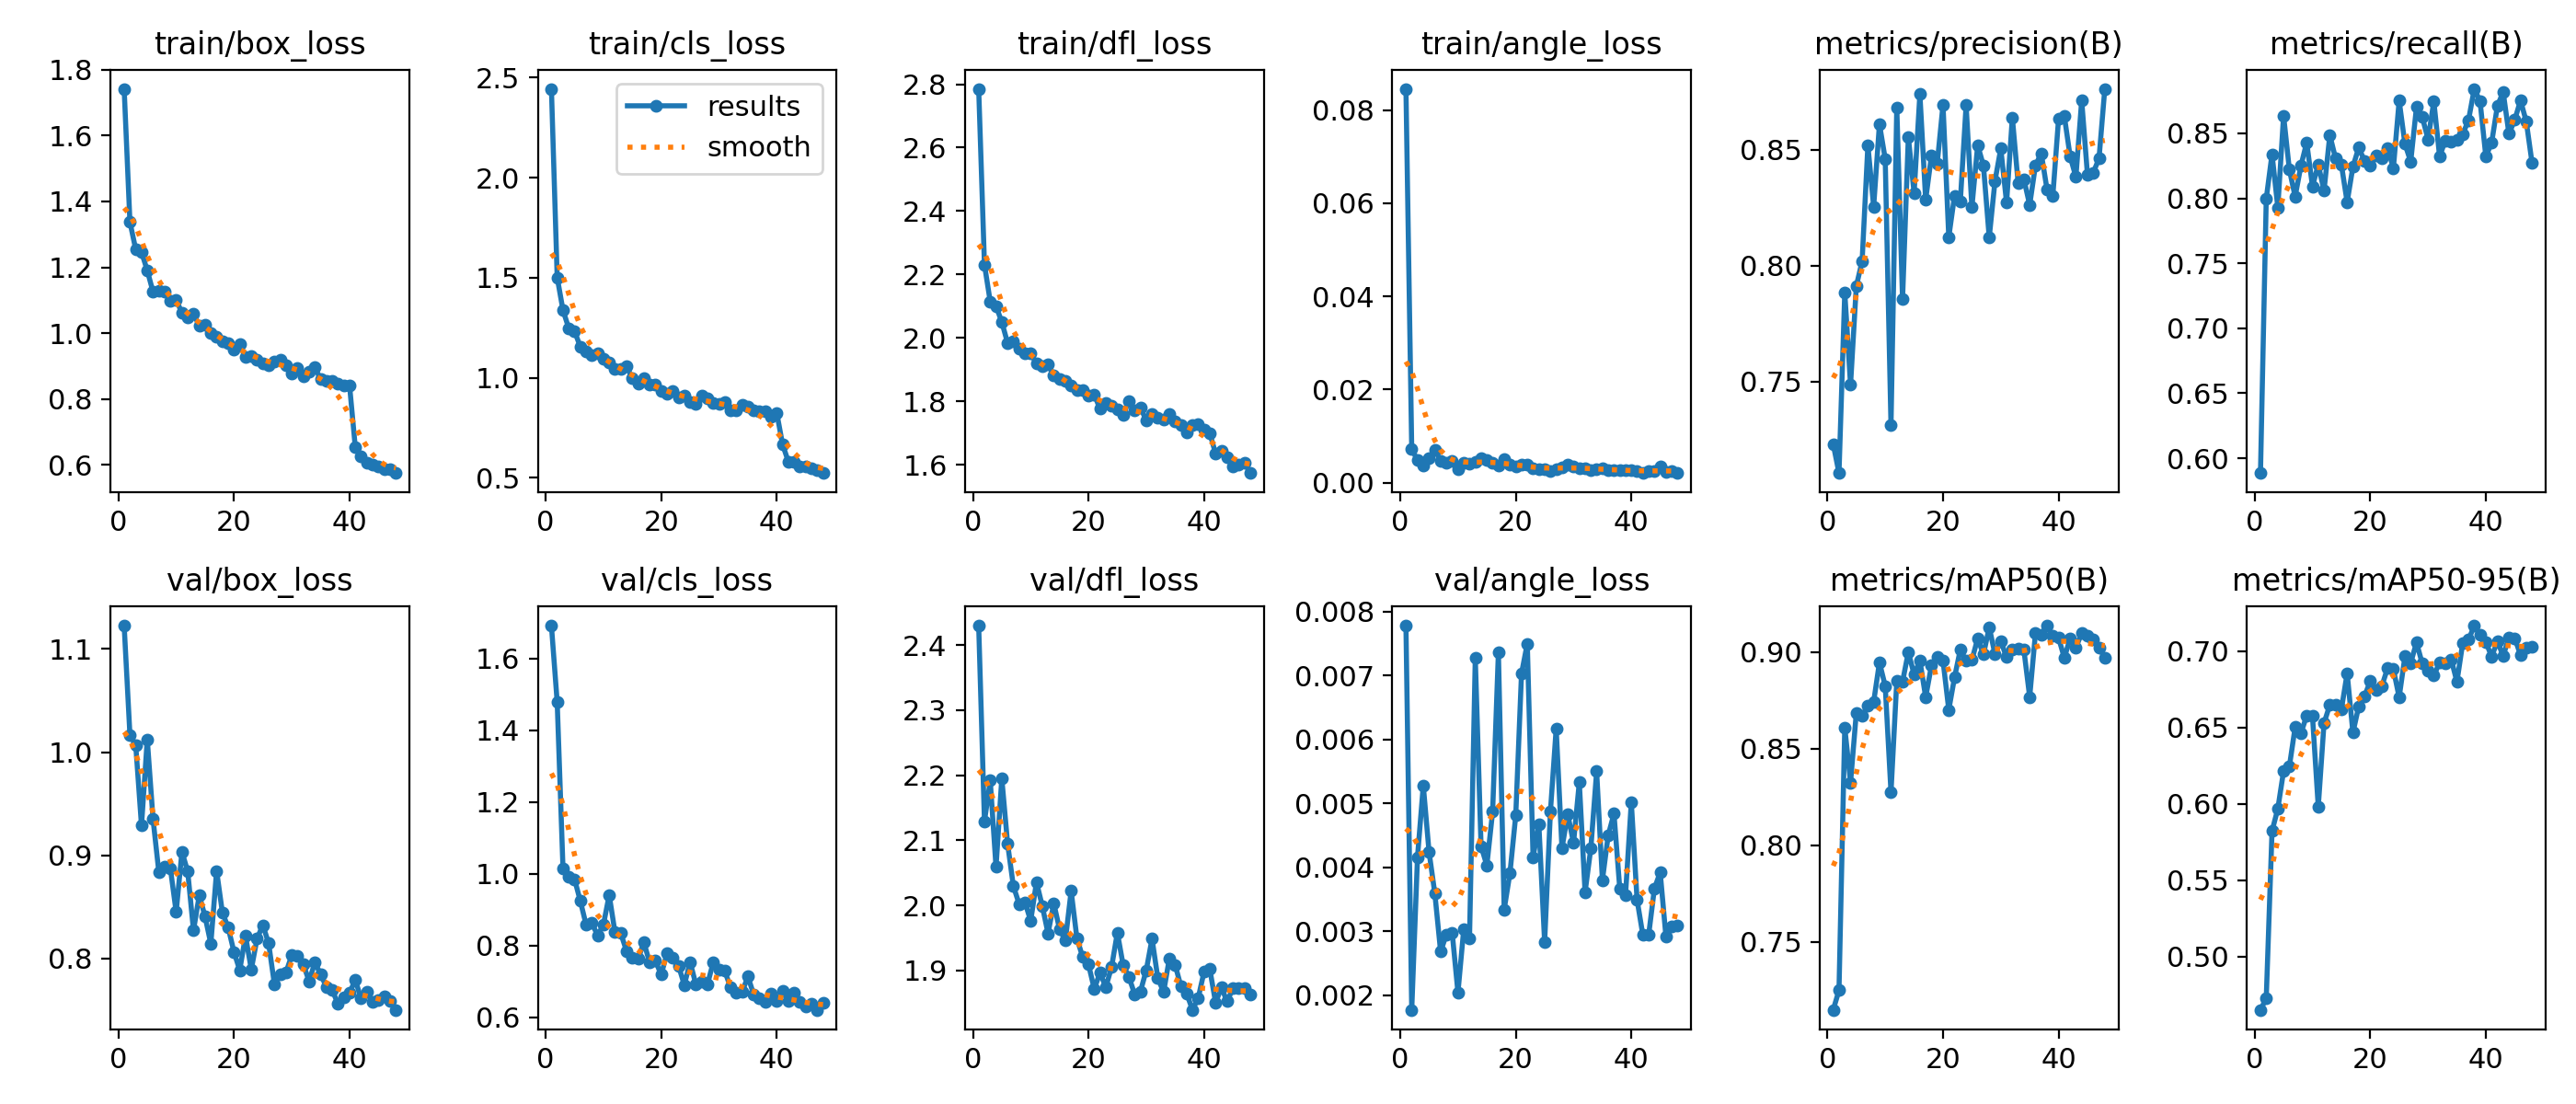

confusion_matrix.png


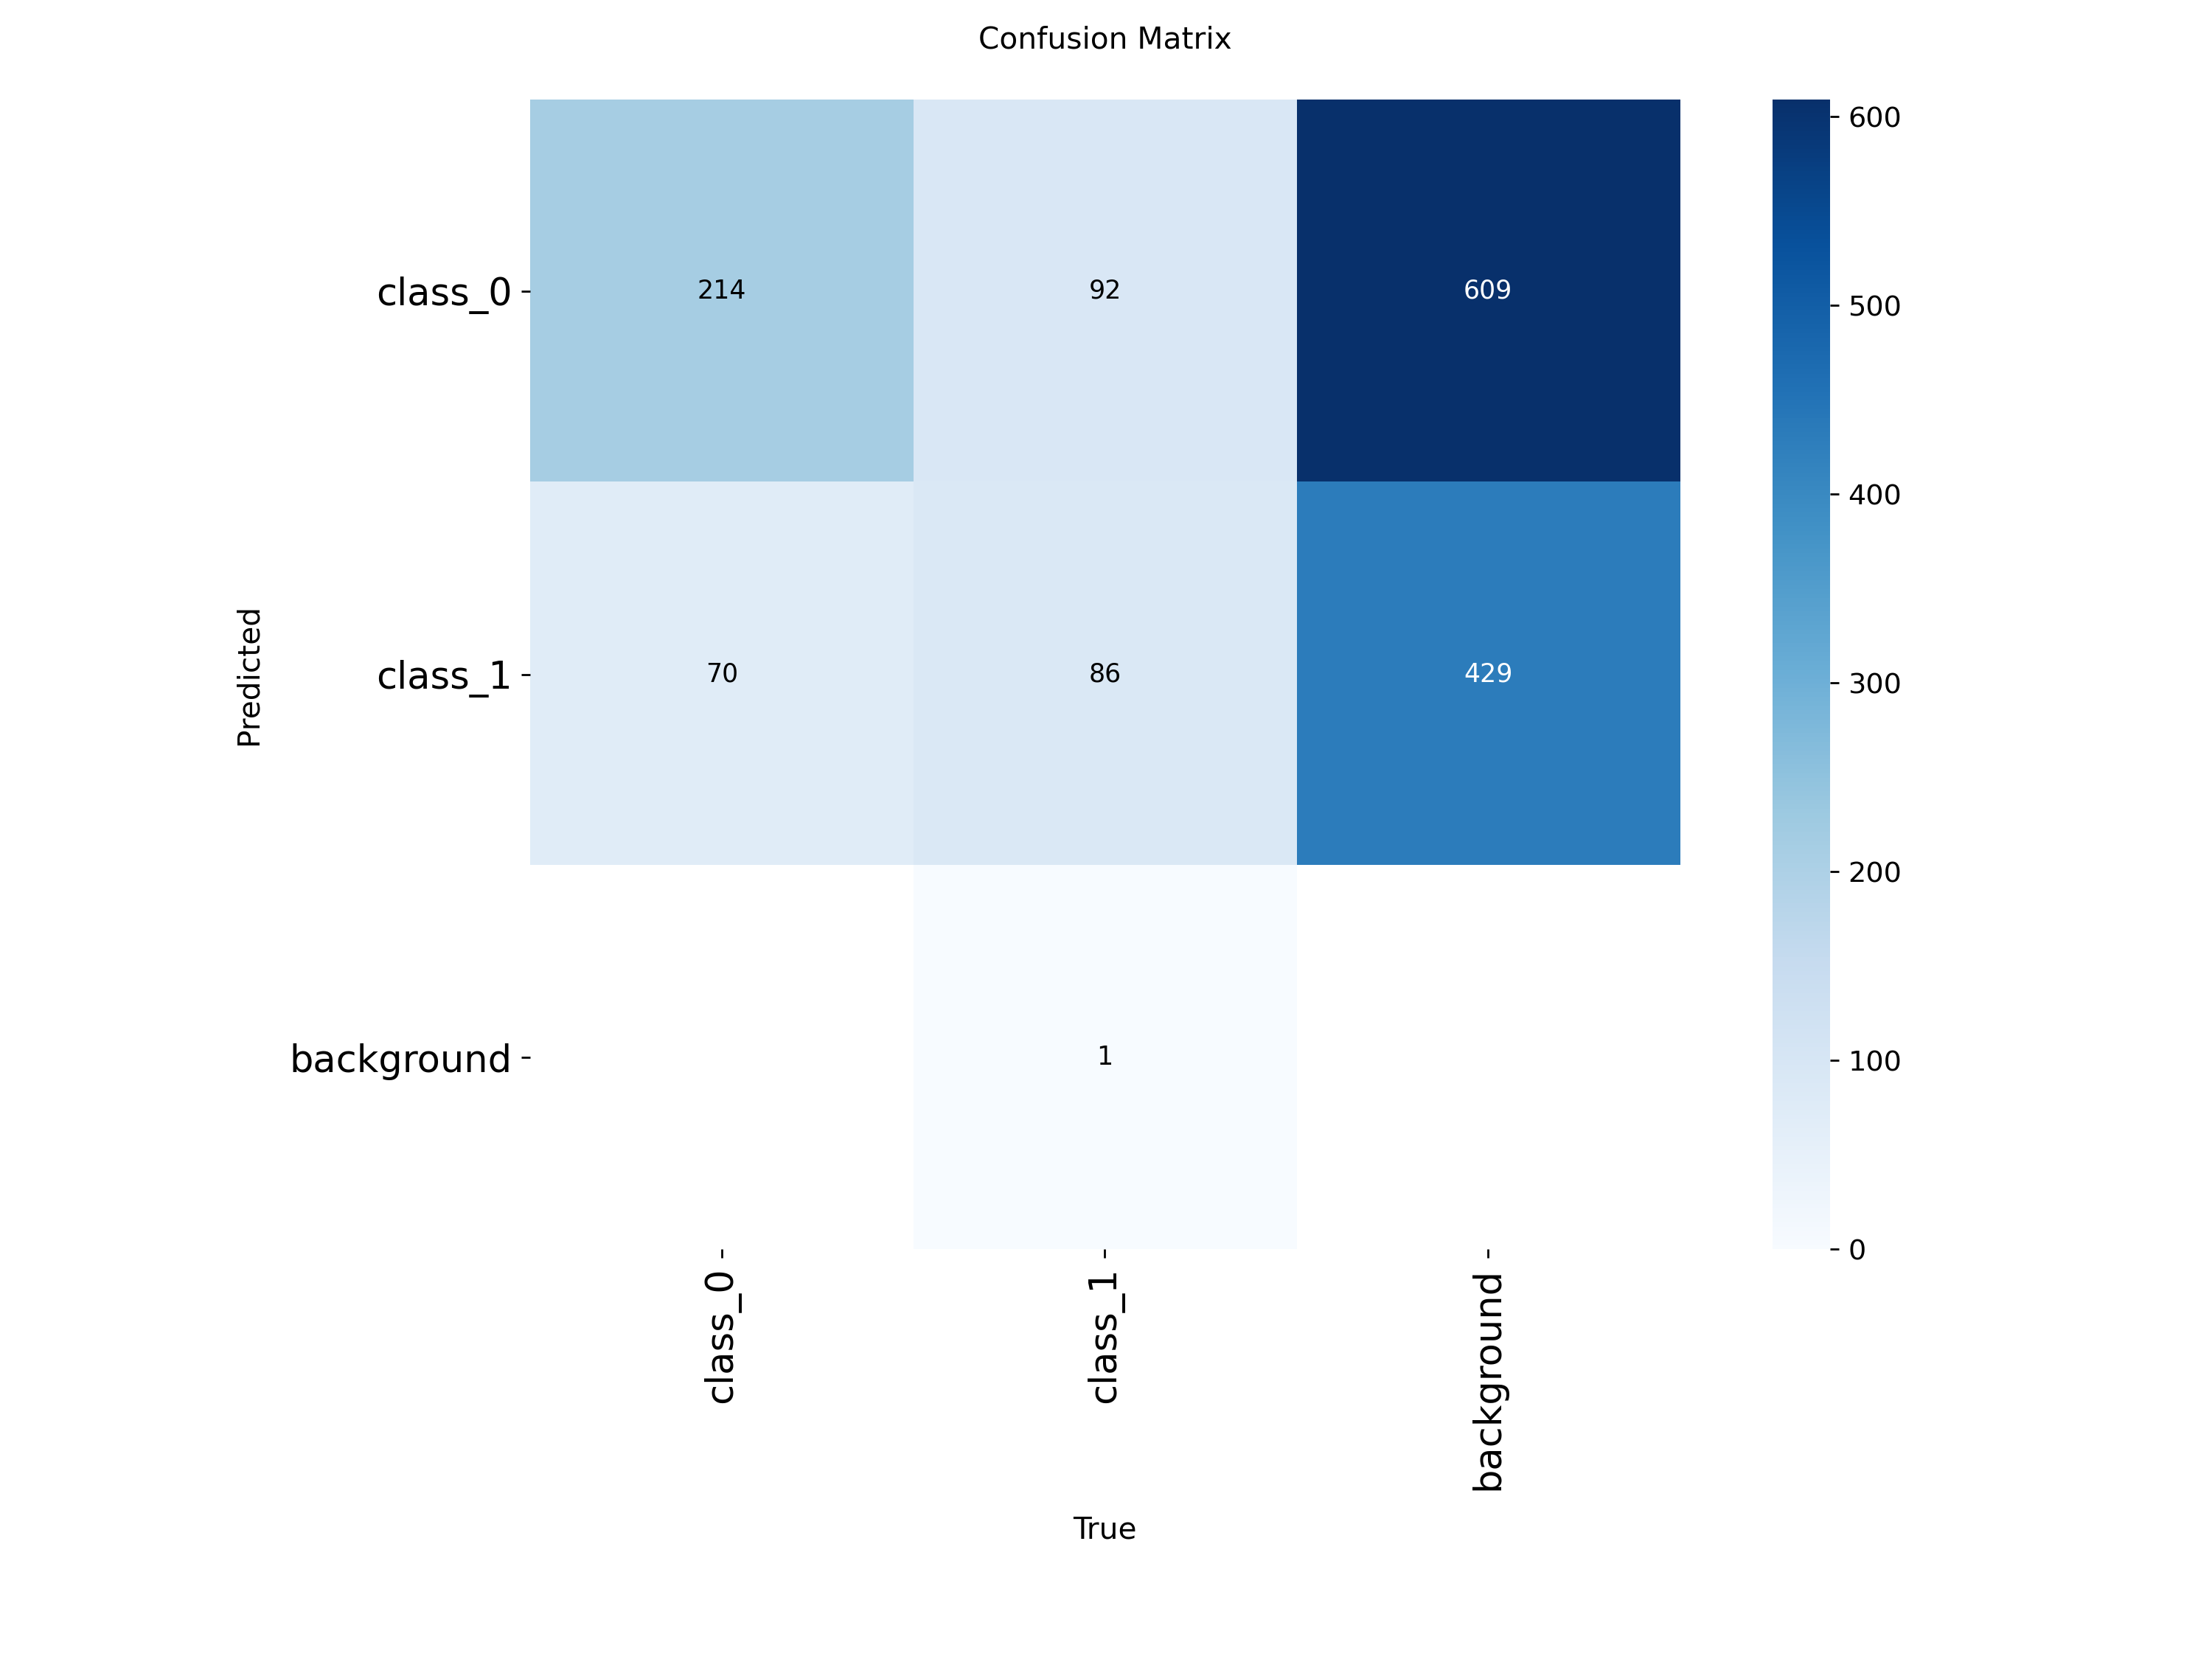

Not found yet: PR_curve.png


In [10]:
from IPython.display import Image as IPyImage, display
results_dir = Path("/content/runs/paddy_weed_obb/yolo11n_obb")
for filename in ["results.png", "confusion_matrix.png", "PR_curve.png"]:
    p = results_dir / filename
    if p.exists():
        print(filename)
        display(IPyImage(filename=str(p)))
    else:
        print("Not found yet:", filename)

## 8. Evaluate on the test set

In [9]:
best_weights = results_dir / "weights" / "best.pt"
if not best_weights.exists():
    raise FileNotFoundError(f"Model weights not found at {best_weights}")
best_model = YOLO(str(best_weights))
test_metrics = best_model.val(data=str(FIXED_YAML), split="test", imgsz=512)
print(test_metrics)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-obb summary (fused): 109 layers, 2,654,113 parameters, 0 gradients, 6.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2186.7±524.4 MB/s, size: 65.3 KB)
val: Scanning /content/paddy_weed_dataset/test/labels... 130 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 130/130 1.9Kit/s 0.1s
val: New cache created: /content/paddy_weed_dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.8it/s 3.2s
                   all        130        189      0.915      0.781      0.861      0.696
               class_0         59         93      0.867      0.763      0.873      0.738
               class_1         71         96      0.962      0.799       0.85      0.653
Speed: 2.7ms preprocess, 5.2ms inference, 0.0ms loss, 6.5ms postprocess per image
Results saved to /content/runs/obb/val
ultralytics.utils.metrics.O

## 9. Run detection on your own field images

Saving agri_0_352_jpeg.rf.c5ae90e52456ac59a88f5e947d522281.jpg to agri_0_352_jpeg.rf.c5ae90e52456ac59a88f5e947d522281.jpg

0: 512x512 2 class_1s, 9.6ms
Speed: 0.8ms preprocess, 9.6ms inference, 2.5ms postprocess per image at shape (1, 3, 512, 512)
Results saved to /content/paddy_weed_predictions/field_images
agri_0_352_jpeg.rf.c5ae90e52456ac59a88f5e947d522281.jpg


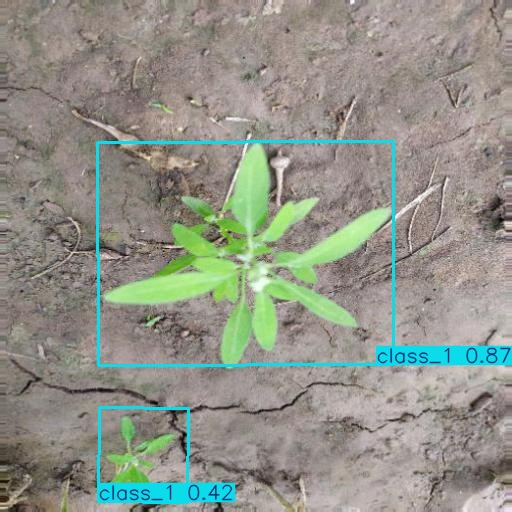

In [12]:
from google.colab import files
uploaded_test = files.upload()  # Upload one or more JPG/PNG field images
image_paths = [name for name in uploaded_test if name.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))]
if not image_paths:
    print("No image files uploaded.")
else:
    predictions = best_model.predict(source=image_paths, imgsz=512, conf=0.25, save=True, project="/content/paddy_weed_predictions", name="field_images")
    for pred in predictions:
        print(pred.path)
        display(IPyImage(filename=pred.plot()[:, :, ::-1].copy() if False else str(Path("/content/paddy_weed_predictions/field_images") / Path(pred.path).name)))

## 10. Export detections as candidate targets

OBB detections provide four polygon corners per object. The centroid below is an **image pixel coordinate**, not a physical position on the machine. Before moving a cutter, you must calibrate camera-to-ground coordinates and add a safe, tested control system with an emergency stop and actuator limit switches.

In [13]:
import pandas as pd

rows = []
for img_path in image_paths:
    pred_list = best_model.predict(source=img_path, imgsz=512, conf=0.25, verbose=False)
    for pred in pred_list:
        if pred.obb is None or len(pred.obb) == 0:
            continue
        polys = pred.obb.xyxyxyxy.cpu().numpy()  # (N, 4, 2) pixel corners
        clss = pred.obb.cls.cpu().numpy().astype(int)
        confs = pred.obb.conf.cpu().numpy()
        for poly, cls_id, conf in zip(polys, clss, confs):
            cx, cy = poly.mean(axis=0)
            rows.append({
                "image": Path(img_path).name,
                "class_id": int(cls_id),
                "class_name": best_model.names[int(cls_id)],
                "confidence": float(conf),
                "centroid_x_px": float(cx),
                "centroid_y_px": float(cy),
                "corners_xy_px": poly.tolist()
            })

df = pd.DataFrame(rows)
display(df.head(20))
csv_path = "/content/paddy_weed_obb_detections.csv"
df.to_csv(csv_path, index=False)
print("Saved:", csv_path)
files.download(csv_path)

,image,class_id,class_name,confidence,centroid_x_px,centroid_y_px,corners_xy_px
0,agri_0_352_jpeg.rf.c5ae90e52456ac59a88f5e947d5...,1,class_1,0.874554,245.784424,253.647079,"[[393.7128601074219, 364.8953857421875], [393...."
1,agri_0_352_jpeg.rf.c5ae90e52456ac59a88f5e947d5...,1,class_1,0.420279,143.555557,454.955505,"[[98.811767578125, 501.706787109375], [187.150..."


Saved: /content/paddy_weed_obb_detections.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Download trained model weights

In [14]:
from google.colab import files
files.download(str(best_weights))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>